# Día 3 — Clasificación: árbol, bosque, KNN y SVM

Del número a una clase y de una clase a una decisión: cuatro enfoques sobre el **mismo ejemplo**.

## Objetivos de aprendizaje

- Definir un problema de clasificación binaria y el momento en que se hace la predicción.
- Explicar desbalance, baseline, nodo/hoja e impureza Gini antes de ajustar un árbol.
- Construir una matriz de confusión e interpretar Accuracy, Precision, Recall y F1.
- Comparar árbol, Random Forest, KNN y SVM sobre las mismas filas de Validation.
- Elegir una estrategia según los errores que importan y reservar Test para el final.


**Dataset:** Bank Marketing de UCI en `datos/bank_marketing_uci.csv`; fuente y licencia en `datos/README.md`.

## Antes de empezar: ¿qué es un problema de clasificación?

En aprendizaje supervisado tenemos ejemplos del pasado. Cada ejemplo contiene datos de entrada —que llamamos X— y una respuesta conocida —que llamamos y—. Entrenamos un modelo con esos ejemplos para que, al recibir una fila nueva, estime una respuesta.

<p align="center">
    <img src="../material_apoyo/classification.png" width="350">
</p>

La primera pregunta es: ¿qué tipo de respuesta queremos obtener?

- En regresión, la respuesta es una cantidad numérica. Por ejemplo: «¿cuánto crecerá el PIB?». Una predicción podría ser 2,4 %. Nos importa qué tan lejos está ese número del valor real: predecir 2,4 % cuando ocurrió 2,6 % es un error menor que predecir 8 %.
- En clasificación, la respuesta es una categoría. Por ejemplo: «¿el cliente contratará un depósito?». Las respuestas posibles son yes y no. El modelo debe asignar una de esas clases a cada contacto nuevo.

Imagina que conocemos de una persona su edad, ocupación y antecedentes de contacto. Si preguntamos «¿cuánto dinero depositará?», buscamos una cantidad y planteamos una regresión. Si preguntamos «¿contratará el depósito: sí o no?», buscamos una categoría y planteamos una clasificación. Los datos de entrada podrían parecerse; lo que define el tipo de problema es la respuesta que queremos predecir.

En este notebook haremos clasificación binaria, porque hay dos clases: no y yes. Llamaremos clase positiva a yes, ya que queremos estudiar especialmente cuántos posibles suscriptores detectamos. «Positiva» no significa «buena» ni implica que el modelo esté seguro: es el nombre que damos a la clase de interés. Otros problemas pueden tener más de dos clases; por ejemplo, clasificar una solicitud como «riesgo bajo», «medio» o «alto».

Un clasificador aprende relaciones entre los datos de entrada y las respuestas históricas. No conoce por sí solo el costo de equivocarse. Decir yes cuando la respuesta real era no puede causar un contacto innecesario; decir no cuando era yes puede hacer perder una oportunidad. Por eso no bastará con contar aciertos: más adelante examinaremos qué tipos de errores comete.

Finalmente, debemos definir cuándo se usará la predicción. Aquí queremos decidir antes de iniciar una llamada a quién contactar. Podemos usar datos disponibles en ese momento, pero no duration, que indica cuánto duró la llamada y solo se conoce después. Incluirla sería darle al modelo una pista del futuro que no tendrá cuando lo utilicemos de verdad.

### Una clase no es lo mismo que una probabilidad

Supongamos que queremos decidir si contactamos a una persona para ofrecerle un depósito. Al pasar sus datos al modelo, predict() puede devolver yes. Eso significa: «según la regla de decisión del modelo, esta persona pertenece a la clase de quienes contratarían». No significa que vaya a contratar con certeza. Del mismo modo, una respuesta no no significa que sea imposible que contrate.

¿Cómo llega el modelo a esa respuesta? Algunos clasificadores calculan primero un valor intermedio o score: una señal que ayuda a situar a la persona de un lado u otro de la frontera de decisión. Un score mayor puede indicar más evidencia a favor de yes, pero no debemos leerlo automáticamente como una probabilidad. Por ejemplo, un score de 2 no quiere decir «2 %» ni «dos veces más probable».

Algunos modelos también pueden entregar una probabilidad estimada, como 0,70. Se interpretaría como una estimación del 70 % bajo ese modelo, no como una garantía de que esa persona contratará. Además, esas probabilidades pueden necesitar una comprobación de calibración: entre muchas personas a quienes se les asignó aproximadamente 70 %, ¿contrató realmente cerca del 70 %?

Finalmente, una regla de decisión convierte la señal del modelo en yes o no. Si hacemos más fácil asignar yes, normalmente detectaremos más posibles suscriptores, pero también contactaremos a más personas que no contratarán. Si somos más exigentes para asignar yes, haremos menos contactos innecesarios, pero podríamos dejar pasar oportunidades. En este notebook, SVM (SVC) usa su frontera de decisión predeterminada; su salida 0 o 1 es una clase, no una probabilidad de 0 % o 100 %.

### Error de clasificación y decisiones económicas

Imaginemos dos personas. A la primera, el modelo le asigna yes, la llamamos y no contrata: hicimos un contacto que no produjo una suscripción. Esto es un falso positivo. A la segunda, el modelo le asigna no, no la llamamos, pero sí habría contratado: dejamos pasar una posible oportunidad. Esto es un falso negativo.

No siempre conviene reducir ambos errores de la misma manera. Si llamar cuesta poco y perder una suscripción potencial cuesta mucho, podríamos aceptar más contactos innecesarios con tal de encontrar más personas que sí contratarían. Más adelante veremos que Recall ayuda a responder: «de quienes realmente eran yes, ¿a cuántos encontramos?». En cambio, si cada llamada requiere mucho tiempo o dinero, nos interesará que las personas señaladas como yes tengan más posibilidades de contratar. Precision ayuda a responder: «de quienes marcamos como yes, ¿cuántos realmente lo eran?».

Por eso, el modelo con más aciertos totales no es necesariamente el más útil. Primero debemos definir qué decisión se tomará, cuánto cuesta cada tipo de error y cuántos contactos podemos realizar. Después miraremos la matriz de confusión y las métricas para saber qué modelo se ajusta mejor a esa necesidad. Los datos históricos nos ayudan a comparar opciones, pero el algoritmo no decide por nosotros cuánto vale una llamada o una oportunidad perdida.

# 0. Librerías

Las librerías utilizadas forman parte de una instalación habitual de Anaconda / scikit-learn.

In [50]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

### Ubicación de los datos

Jupyter interpreta las rutas relativas desde su **directorio de trabajo actual**, no desde la ubicación del archivo `.ipynb`. Si se ejecuta desde la raíz del proyecto, el CSV está en `datos/`; si se ejecuta desde `notebooks/`, está en `../datos/`. La celda siguiente elige entre esas dos ubicaciones sin definir una función.


In [51]:
# Sirve si Jupyter se inició desde modulo3_ml/ o desde modulo3_ml/notebooks/.
DATA_DIR = Path("../datos")
ARCHIVO = DATA_DIR / "bank_marketing_uci.csv"
print("Archivo que se cargará:", ARCHIVO.resolve())


Archivo que se cargará: C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\bank_marketing_uci.csv


# 1. El problema: ¿a quién conviene contactar primero?

Imaginemos que un banco tiene una lista de personas a quienes podría llamar para ofrecerles un depósito a plazo, pero el equipo dispone de tiempo limitado. Antes de llamar, quiere ordenar esa lista para prestar atención a quienes, según los datos históricos, podrían tener mayor posibilidad de contratar. El problema no es saber cuánto dinero depositará cada persona, sino estimar una respuesta de dos clases: ¿contratará (yes) o no (no)? Por eso se trata de un problema de clasificación.

Para practicar usaremos Bank Marketing, un conjunto público de campañas de un banco portugués. Cada fila registra un contacto realizado en el pasado. Las columnas describen características de la persona y de la campaña; la columna y indica si ese contacto terminó o no en una contratación. Entrenaremos los modelos con contactos históricos cuya respuesta ya conocemos y les pediremos que predigan la clase de otros contactos que dejamos aparte para evaluarlos.

La decisión debe poder tomarse antes de iniciar la llamada. Por eso solo usaremos información que podría estar disponible entonces. No incluiremos duration, la duración de la llamada: aunque ayuda a predecir la respuesta en los datos históricos, aún no existe cuando decidimos a quién llamar.

Equivocarse tiene dos consecuencias distintas: llamar a alguien que no contratará consume tiempo; dejar fuera a alguien que sí habría contratado puede representar una oportunidad perdida. Compararemos árbol de decisión, Random Forest, KNN y SVM sobre los mismos datos y con las mismas métricas para observar qué errores comete cada uno, no solo cuántas respuestas acierta en total. Este es un ejercicio didáctico con datos portugueses: sus resultados no describen a clientes del Banco Central del Ecuador ni justifican aplicarlo allí directamente.

In [52]:
bank = pd.read_csv(ARCHIVO, sep=";")  # El CSV de UCI separa columnas con punto y coma.

print("Dimensiones (filas, columnas):", bank.shape)
print("Columnas:", list(bank.columns))
bank.head()


Dimensiones (filas, columnas): (41188, 21)
Columnas: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [53]:
print("Distribución de y:")
print(bank["y"].value_counts())
print("Proporciones:")
print((bank["y"].value_counts(normalize=True) * 100).round(2))
print("Nulos por columna:")
print(bank.isna().sum().sort_values(ascending=False).head())
print("Categoría unknown:")
print(bank.select_dtypes("object").eq("unknown").sum().sort_values(ascending=False).head())


Distribución de y:
y
no     36548
yes     4640
Name: count, dtype: int64
Proporciones:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64
Nulos por columna:
age              0
campaign         0
nr.employed      0
euribor3m        0
cons.conf.idx    0
dtype: int64
Categoría unknown:
default      8597
education    1731
housing       990
loan          990
job           330
dtype: int64


### Conocer los datos antes de entrenar
Bank Marketing proviene del UCI Machine Learning Repository, un repositorio público de conjuntos de datos mantenido por la Universidad de California en Irvine. Contiene registros de campañas de un banco portugués. Cada fila corresponde a un contacto histórico y la columna y registra el resultado: yes si hubo contratación de un depósito a plazo y no si no la hubo.

Antes de construir un modelo, necesitamos responder preguntas sencillas: ¿cuántos contactos hay?, ¿cuántos terminaron en contratación?, ¿hay datos ausentes?, ¿qué significan las columnas? Si no conocemos esto, podríamos interpretar mal incluso un porcentaje de aciertos aparentemente alto.

### Leer el primer resumen, línea por línea

La salida muestra 41 188 contactos. De ellos, 36 548 tienen y = no y 4 640 tienen y = yes. value_counts() cuenta las filas de cada clase. Con normalize=True obtiene su proporción; en este notebook la multiplicamos por 100 para mostrarla como porcentaje: 88,73 % no y 11,27 % yes.

La tabla «Nulos por columna» busca celdas que Pandas reconoce como ausentes. Solo muestra las primeras cinco columnas del recuento, así que ver cinco ceros no demuestra por sí solo que ninguna otra columna tenga nulos. En cambio, unknown es una palabra escrita dentro de algunas celdas, no un nulo de Pandas. Por ejemplo, default contiene 8 597 registros con la categoría unknown. Esto significa que debemos examinar qué se desconoce y decidir cómo tratarlo; no debemos borrar automáticamente esas filas ni afirmar que son 8 597 nulos.

Entre las variables, age representa la edad y job la ocupación. campaign indica cuántos contactos se realizaron durante la campaña actual; previous se refiere a contactos anteriores. La columna y es la respuesta que queremos predecir. Más adelante separaremos esta respuesta de las columnas que usará el modelo como información de entrada.

### ¿Qué es el desbalance de clases y por qué importa?
Hay desbalance de clases cuando una respuesta aparece mucho más que la otra. Aquí casi 89 de cada 100 contactos terminaron en no, mientras que solo 11 de cada 100 terminaron en yes. no es la clase mayoritaria y yes la minoritaria. Nos interesa especialmente detectar yes, por lo que la llamaremos clase positiva; «positiva» es solo una etiqueta de análisis, no un juicio sobre las personas.

Consideremos una regla muy simple: responder siempre no, sin mirar edad, ocupación ni ninguna otra columna. Esta regla se llama modelo de referencia o baseline: sirve para saber qué se consigue sin un algoritmo sofisticado. Acertaría aproximadamente el 88,73 % de los contactos, porque esa es la proporción de no. Sin embargo, no encontraría ni uno solo de los 4 640 yes. Su porcentaje de aciertos sería alto, pero no ayudaría a identificar posibles suscriptores. Por eso el desbalance cambia la forma en que debemos evaluar los modelos.

### No todos los «aciertos» responden a la misma pregunta

Accuracy significa proporción de aciertos totales: de todos los contactos, ¿en cuántos coincidió la predicción con la respuesta real? Es fácil de entender, pero en estos datos puede quedar dominada por la abundancia de no.

Para evaluar la clase yes, distinguiremos dos errores:
- Falso positivo: el modelo predijo yes, pero el resultado histórico fue no. En el ejemplo de la campaña, representa una alerta que no terminó en contratación.
- Falso negativo: el modelo predijo no, pero el resultado histórico fue yes. Representa un contacto positivo que el modelo no identificó como tal.
Con esa distinción podemos formular preguntas más útiles:
- Precision: de todos los contactos que el modelo marcó como yes, ¿qué proporción era realmente yes? Ayuda a valorar cuántas alertas positivas fueron acertadas.
- Recall: de todos los contactos que realmente eran yes, ¿qué proporción encontró el modelo? Ayuda a valorar cuántos positivos dejó escapar.
- F1: reúne Precision y Recall en una sola cifra y penaliza que una de las dos sea muy baja. Es útil para resumir ese equilibrio, pero no decide por sí sola qué tipo de error cuesta más.

Por ejemplo, un modelo podría marcar a muy pocas personas como yes y acertar casi todas: tendría buena Precision, pero podría dejar escapar muchos suscriptores y tener bajo Recall. Otro podría encontrar a más suscriptores, pero generar más alertas equivocadas. Veremos los números concretos en la matriz de confusión, una tabla que cruza la respuesta real con la predicción.

### Una variable que no podemos utilizar: duration
duration indica cuánto duró la llamada. Podría ayudar mucho a distinguir yes de no en los registros históricos, pero nuestro problema consiste en decidir antes de llamar. En ese momento todavía no sabemos cuánto durará la conversación.

Usar duration sería una fuga de información (data leakage): dar al modelo, durante el entrenamiento y la evaluación, una pista que no estará disponible cuando deba tomar la decisión real. Podríamos obtener resultados muy buenos en el notebook que luego no podríamos reproducir al usar el modelo. Por eso excluimos esa columna antes de entrenar.

## Preparar una comparación común y sin fuga

Queremos comparar cuatro maneras de responder a **la misma pregunta**: ¿el contacto terminó en `yes` o `no`? Si un modelo aprendiera con más contactos que otro, o se evaluara con personas distintas, sus porcentajes no serían directamente comparables. Por eso fijamos primero **una muestra común** de alrededor de 12 000 contactos y después los mismos tres subconjuntos para todos los modelos.

La base completa contiene 41 188 contactos. La muestra mantiene aproximadamente la proporción de `yes` y `no` de la base original; esto se llama **muestreo estratificado**. Trabajar con una parte permite probar KNN y SVM en un computador de clase. No afirmaremos que entrenar con 12 000 personas produzca el mismo resultado que hacerlo con las 41 188. La preparación de números y categorías también se aprenderá **solo a partir de Train**: de lo contrario, Validation o Test darían pistas sobre datos que debían permanecer apartados.


### ¿Por qué conservar Train, Validation y Test?

Imagina que estudias para un examen. **Train** son los ejercicios con los que practicas y aprendes reglas. **Validation** son ejercicios nuevos que utilizas para comparar estrategias: si pruebas muchas estrategias y escoges la que más acertó allí, Validation ya influyó en tu decisión. **Test** es el examen final, que mantienes cerrado hasta haber decidido qué estrategia usarás. Si vuelves a modificarla después de mirar Test, ya no es una prueba independiente.

En código, Train sirve además para aprender cómo rellenar ausencias, cómo escalar números y cómo codificar categorías. Validation comparará árbol, bosque, KNN y SVM; Test se consultará **una sola vez al final**. Dividiremos aproximadamente 70 % / 15 % / 15 %: con cerca de 12 000 contactos serán unos 8 400 / 1 800 / 1 800. La opción `stratify=y` procura conservar en cada parte la proporción de `yes` y `no`, para que una partición no resulte mucho más fácil por contener casi solo negativos. `random_state=42` fija el sorteo para poder repetir el ejercicio: 42 no tiene ninguna propiedad estadística especial.

Este reparto aleatorio contesta cómo funcionan los modelos en contactos históricos mezclados de manera semejante. **No prueba** por sí solo cómo funcionarían en una campaña futura, donde podrían cambiar las personas y las tasas de contratación.


In [54]:
# Una muestra única: evita enfrentar métricas obtenidas con tamaños de entrenamiento distintos.
datos = bank.groupby("y", group_keys=False).sample(frac=min(12000 / len(bank), 1), random_state=42)
y = datos["y"].map({"no": 0, "yes": 1})  # 1 será la clase positiva en todas las métricas.
X = datos.drop(columns=["y", "duration"])  # duration aún no se conoce antes de la llamada.
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=.50, random_state=42, stratify=y_rest)
num = X.select_dtypes(include="number").columns.tolist()
cat = X.select_dtypes(exclude="number").columns.tolist()
# Distancias y márgenes necesitan escalado; categorías se transforman sin inventarles orden.
pre = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat)
])
# Los árboles usan el mismo X/particiones, pero no necesitan escalar números para cortar por umbrales.
pre_arbol = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat)
])
print("Train / Validation / Test:", X_train.shape, X_val.shape, X_test.shape)
print("Proporción yes en Train/Val/Test:", [round(float(s.mean()), 3) for s in (y_train, y_val, y_test)])


Train / Validation / Test: (8400, 19) (1800, 19) (1800, 19)
Proporción yes en Train/Val/Test: [0.113, 0.113, 0.113]


### Leer el código de preparación, paso a paso

1. `bank.groupby("y").sample(...)` toma aproximadamente la **misma fracción de cada clase**; así la muestra de clase conserva el desbalance original. `y` guarda la respuesta (`no → 0`, `yes → 1`). Los números son etiquetas, **no probabilidades**. `X` guarda los datos de entrada: quitamos `y` para no mostrar la respuesta y `duration` porque no se conoce antes de llamar.
2. Dos divisiones `train_test_split` crean Train, Validation y Test. Separamos **antes** de calcular medianas, escalas o categorías. Después `num` identifica columnas numéricas y `cat` las categóricas: edad y ocupación requieren tratamientos distintos.
3. En las columnas numéricas, `SimpleImputer(strategy="median")` rellenará un valor ausente con la mediana **aprendida en Train**. Para KNN y SVM, `StandardScaler` también aprenderá allí la media y la desviación estándar para poner las magnitudes en escalas comparables. Si una variable ronda 5 000 y otra 40, la primera no debe dominar una distancia únicamente por su unidad.
4. En las columnas categóricas, una ausencia reconocida por Pandas se rellena con la categoría más frecuente de Train. `OneHotEncoder` crea columnas 0/1, como `job_admin` y `job_technician`, sin inventar que una ocupación sea «mayor» que la otra. La palabra literal `unknown` ya presente en la base es una **categoría**, no un nulo que este imputador deba rellenar. `handle_unknown="ignore"` permite transformar una categoría nueva en Validation/Test sin romper la ejecución.
5. `pre` es el preparador para KNN/SVM, sensibles a escalas. `pre_arbol` rellena números y codifica categorías, pero **no escala**: para preguntar «¿edad ≤ 40?», cambiar de unidades no cambia el orden de las edades. Ambos preparadores reciben las mismas columnas originales y se ajustarán dentro de sus respectivos Pipelines **solo con Train**.

Las últimas líneas imprimen el tamaño y la proporción de `yes` en cada parte. Comprueba que las tres proporciones se parezcan antes de interpretar las métricas.


### Un límite del escalado y de One-Hot

Escalar no hace que dos personas sean «objetivamente cercanas»: evita que una variable numérica domine la distancia **solo por sus unidades**. One-Hot impide inventar un orden entre ocupaciones, pero tampoco determina cuánto debería importar `job` frente a `age`. La representación que elegimos influye en quién queda cerca para KNN y en la frontera que aprende SVM. Por ejemplo, incluir muchas columnas One-Hot para una característica puede cambiar la geometría de las distancias.

Por eso comparamos el resultado en Validation y documentamos las variables y transformaciones empleadas. Un porcentaje alto no demuestra que la codificación sea la única correcta ni que la distancia matemática equivalga a similitud económica entre personas.


### ¿Por qué el Pipeline recibe columnas originales?

En `X_train` seguimos viendo `age` como número y `job` como texto. `ColumnTransformer` mira las listas `num` y `cat` y envía cada columna por el tratamiento que acabamos de explicar. Un **Pipeline** une ese tratamiento al clasificador para que se repitan siempre los mismos pasos: al llamar a `.fit(X_train, y_train)` aprende medianas, escalas, categorías y reglas del modelo **en Train**; al llamar a `.predict(X_val)` transforma Validation con lo ya aprendido y produce clases sin volver a ajustar nada.

Si calculásemos la media o las categorías usando todas las filas antes de dividir, Validation y Test habrían influido en la preparación. Eso sería una **fuga de información**: una pista de las filas reservadas entraría al entrenamiento. El Pipeline disminuye ese riesgo y evita preparar de forma distinta cada conjunto.


## Una referencia sencilla antes del primer árbol

Un **baseline** es una regla intencionalmente simple contra la cual mediremos modelos más elaborados. Nuestro baseline responde siempre `no`, la clase que ocupa casi 89 de cada 100 contactos. Acertará muchos casos por la frecuencia de `no`, **sin haber aprendido nada sobre qué distingue a quienes contratan**. `DummyClassifier(strategy="most_frequent")` implementa esa regla.

Primero compararemos cuántos `yes` hay realmente en Validation con cuántos `yes` predice el baseline. Después, cuando entendamos la matriz de confusión, calcularemos sus métricas junto a las del árbol. Así sabremos por qué una Accuracy alta puede ocultar que el modelo no detecta ningún positivo.


### Clase mayoritaria y clase que queremos detectar

Al convertir `no` en 0 y `yes` en 1, fijamos `yes` como **clase positiva**, es decir, la que queremos seguir de cerca. «Positiva» no promete que el modelo acierte ni expresa una opinión sobre la persona. `DummyClassifier` ignora edad, ocupación y todas las demás columnas; aprende únicamente cuál etiqueta aparece más en **Train** y la repite al predecir Validation.

Si `no` es la mayoría, el baseline no marcará ningún contacto como `yes`. Su `predict()` devuelve clases 0/1, **no probabilidades**. Esta referencia nos ayudará a preguntar algo mejor que «¿cuántos aciertos hubo?»: «¿encontramos siquiera alguno de los contactos cuya respuesta histórica fue `yes`?».


In [55]:
# La referencia mayoritaria ignora X: la usamos para no elogiar una Accuracy engañosa.
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_base = baseline.predict(X_val)
print("Frecuencia real en Validation:", y_val.value_counts().sort_index().to_dict())
print("Predicciones del baseline:", pd.Series(pred_base).value_counts().sort_index().to_dict())


Frecuencia real en Validation: {0: 1597, 1: 203}
Predicciones del baseline: {0: 1800}


### Leer la salida del baseline

La primera línea muestra la **realidad** en Validation: cuántos contactos acabaron en `no` y cuántos en `yes`. La segunda muestra las **predicciones** de la regla: casi todos —en este caso, todos— fueron etiquetados `no`. Compara ambas líneas: cada `yes` real que el baseline llamó `no` es un caso que dejó escapar.

Si `no` representa cerca del 89 %, esta regla acertará aproximadamente ese porcentaje, pero detectará **cero `yes`**. Más adelante veremos esos errores en una tabla de cuatro casillas y calcularemos Accuracy, Precision, Recall y F1. No consideres útil al baseline por el solo hecho de que tenga muchos aciertos globales.


### Pausa de comprensión

De cada 100 contactos, imagina aproximadamente 89 `no` y 11 `yes`. Si predices `no` para todos: ¿cuántos aciertas?, ¿cuántos de los 11 `yes` encuentras? Si llamar cuesta dinero, ¿preferirías llamar a más personas aunque algunas no contraten, o correr el riesgo de dejar pasar posibles suscripciones? Escribe tu criterio antes de mirar cuál modelo obtuvo la mayor métrica.


## Árbol de clasificación: aprender preguntas, no una sola fórmula

Piensa en un pequeño cuestionario. A partir de los contactos de Train, el árbol intenta preguntas como «¿edad ≤ cierto valor?» o «¿la ocupación es `admin`?». Según la respuesta, cada contacto sigue una **rama**. Al final llega a una **hoja**, un grupo de contactos históricos; la clase más frecuente allí determina la predicción usual para una fila nueva que siga el mismo camino. En el Día 2 una hoja entregaba un promedio de crecimiento; ahora entrega `no` o `yes`.

**¿Cómo escoge una pregunta?** Una hoja con diez `no` y cero `yes` está «pura»: todos coinciden. Otra con cinco de cada clase está muy mezclada. El índice de **impureza Gini** mide esa mezcla. Con proporciones $p_{no}$ y $p_{yes}$, $G=1-p_{no}^2-p_{yes}^2$. Vale **0** si todos son de la misma clase y **0,5** cuando ambas clases ocupan la mitad. Si diez contactos se dividen en una rama con cinco `no` y otra con cinco `yes`, ambas ramas tienen Gini 0: en ese ejemplo la pregunta separó perfectamente las clases. El árbol busca preguntas que reduzcan la mezcla promedio de las ramas, teniendo en cuenta cuántos contactos llega a cada una.

Gini ayuda al árbol a **aprender reglas**; no es una métrica de aciertos en Validation. Un árbol muy grande puede crear hojas casi exclusivas para los contactos de Train y fallar con otros. `max_depth` limita cuántas preguntas se encadenan y `min_samples_leaf` exige un mínimo de contactos por hoja. Comprobaremos los errores fuera de Train antes de juzgarlo.


In [56]:
# Cálculo transparente: primero mezcla 50/50, luego dos ramas puras.
def gini(conteos):
    proporciones = np.asarray(conteos) / sum(conteos)
    return 1 - np.sum(proporciones ** 2)

print("Gini raíz (5 no, 5 yes):", gini([5, 5]))
print("Gini ponderado de ramas puras:", (5 * gini([5, 0]) + 5 * gini([0, 5])) / 10)


Gini raíz (5 no, 5 yes): 0.5
Gini ponderado de ramas puras: 0.0


### Del cuestionario al primer modelo

`Pipeline([("prep", pre_arbol), ("model", DecisionTreeClassifier(...))])` une la preparación para árboles y el algoritmo. `.fit(X_train, y_train)` aprende las medianas, las categorías y las preguntas **solo a partir de Train**. Después `.predict(X_val)` aplica esas reglas a contactos que quedaron apartados. No usamos Test ni calculamos nuevas medianas en Validation.

Elegimos `max_depth=5` para no permitir preguntas indefinidas y `min_samples_leaf=30` para evitar hojas basadas en muy pocos contactos. La celda mostrará la profundidad realmente aprendida, el número de hojas y cuántos `yes` predijo. **Más hojas no implican mejor modelo:** falta saber cuántas de esas respuestas fueron correctas.


In [57]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

arbol = Pipeline([
    ("prep", pre_arbol),
    ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=42)),
])
arbol.fit(X_train, y_train)  # Aprende imputación, categorías y divisiones en Train.
pred_arbol_val = arbol.predict(X_val)  # Validation no reajusta ningún paso.
print("Profundidad aprendida:", arbol.named_steps["model"].get_depth())
print("Hojas aprendidas:", arbol.named_steps["model"].get_n_leaves())
print("Predicciones yes en Validation:", int(pred_arbol_val.sum()))


Profundidad aprendida: 5
Hojas aprendidas: 20
Predicciones yes en Validation: 62


### Una predicción aislada no revela todos los errores

Supongamos que el árbol marca 120 contactos como `yes`. Ese número no dice si fueron 120 contrataciones reales o 120 falsas alarmas. También debemos preguntar cuántos `yes` reales etiquetó equivocadamente como `no`. Para responder cruzaremos, **fila por fila**, la clase histórica con la predicción: el resultado es la **matriz de confusión**. Su nombre significa que deja ver qué clases confundió el modelo, no que la tabla sea difícil de leer.


## ¿Qué es una matriz de confusión?

Es una **tabla de conteos** que enfrenta lo que ocurrió con lo que predijo un clasificador. **Cada contacto de Validation entra exactamente en una de sus cuatro casillas.** Las filas representan la clase real (`y_val`); las columnas, la clase predicha (`pred_arbol_val`). Leemos `no` y `yes` en el mismo orden en ambos ejes:

| Clase real ↓ / Predicción → | `no` predicho | `yes` predicho |
| --- | ---: | ---: |
| **`no` real** | **VN:** acertó al decir `no` | **FP:** anunció `yes`, pero fue `no` |
| **`yes` real** | **FN:** anunció `no`, pero fue `yes` | **VP:** acertó al decir `yes` |

**VN** significa verdadero negativo; **FP**, falso positivo; **FN**, falso negativo; **VP**, verdadero positivo. «Positivo» significa `yes`, la clase que decidimos seguir. Las dos casillas diagonales son aciertos (VN y VP); las otras dos son errores (FP y FN).

Ejemplo: entre 110 contactos, imagina 72 VN, 8 FP, 12 FN y 18 VP. Las filas dicen que hubo 80 `no` reales (`72+8`) y 30 `yes` reales (`12+18`). Las columnas dicen que el modelo predijo 84 `no` (`72+12`) y 26 `yes` (`8+18`). Comprueba que las cuatro casillas suman 110 **antes** de calcular porcentajes. Ahora ejecutaremos la matriz **real del árbol en Validation**.


          pred no  pred yes
real no      1573        24
real yes      165        38
VN, FP, FN, VP: 1573 24 165 38


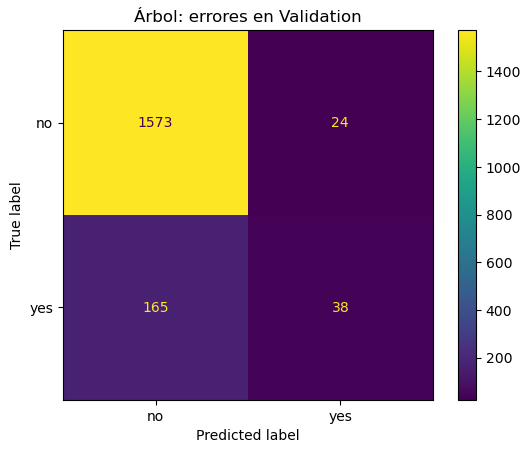

In [58]:
# Orden [0, 1]: filas reales (no, yes), columnas predichas (no, yes).
matriz_arbol = confusion_matrix(y_val, pred_arbol_val, labels=[0, 1])
vn, fp, fn, vp = matriz_arbol.ravel()
print(pd.DataFrame(matriz_arbol, index=["real no", "real yes"],
                   columns=["pred no", "pred yes"]))
print("VN, FP, FN, VP:", vn, fp, fn, vp)
ConfusionMatrixDisplay.from_predictions(y_val, pred_arbol_val, display_labels=["no", "yes"])
plt.title("Árbol: errores en Validation")
plt.show()


## De las cuatro casillas a las métricas

Acabamos de ver **conteos** en la matriz del árbol: cuántas veces acertó `no` o `yes` y cuántas confundió una clase con la otra. Ahora convertiremos esos conteos en **proporciones** para comparar modelos sobre las mismas filas. Cada fórmula toma como denominador el grupo que responde a una pregunta concreta:

| Métrica | Pregunta | Cálculo desde la matriz |
| --- | --- | --- |
| **Accuracy** | ¿Qué fracción de **todos** los contactos fue correcta? | $(VP+VN)/(VP+VN+FP+FN)$ |
| **Precision de `yes`** | Entre los **predichos `yes`**, ¿cuántos eran `yes`? | $VP/(VP+FP)$ |
| **Recall de `yes`** | Entre los **`yes` reales**, ¿cuántos detectamos? | $VP/(VP+FN)$ |
| **F1 de `yes`** | ¿Cómo resumimos Precision y Recall penalizando que una sea muy baja? | $2\,Precision\,Recall/(Precision+Recall)$ |

**No memorices cuatro fórmulas a ciegas:** primero señala en la matriz el grupo de personas que pregunta el denominador. En el ejemplo inventado de 110 contactos usaremos `VN=72`, `FP=8`, `FN=12` y `VP=18`; calcula cada fracción antes de ejecutar la celda siguiente. Si no se predijo ningún `yes`, la Precision queda sin denominador: más adelante el código mostrará 0 por convención de reporte, no porque el baseline haya emitido alertas útiles.


In [59]:
# Ejemplo pequeño para calcular las métricas a mano
VP, VN, FP, FN = 18, 72, 8, 12
accuracy_demo = (VP + VN) / (VP + VN + FP + FN)
precision_demo = VP / (VP + FP)
recall_demo = VP / (VP + FN)
f1_demo = 2 * precision_demo * recall_demo / (precision_demo + recall_demo)
print({"Accuracy": round(accuracy_demo, 3),
       "Precision": round(precision_demo, 3),
       "Recall": round(recall_demo, 3),
       "F1": round(f1_demo, 3)})


{'Accuracy': 0.818, 'Precision': 0.692, 'Recall': 0.6, 'F1': 0.643}


### Convertir los conteos en preguntas útiles

Ahora que sabes leer una matriz, las métricas se pueden entender como **preguntas sobre sus casillas**. Usa el ejemplo inventado de 72 VN, 8 FP, 12 FN y 18 VP (110 contactos):

- **Accuracy (aciertos globales):** de todos los 110, acertamos `72+18=90`; por eso vale `90/110 ≈ 0,818` (81,8 %). Con muchos `no`, puede ser alta aunque dejemos escapar positivos.
- **Precision de `yes`:** entre los **26 que marcamos `yes`**, 18 lo eran realmente: `18/(18+8) ≈ 0,692` (69,2 %). Responde «¿cuántas alertas positivas fueron acertadas?».
- **Recall de `yes`:** entre los **30 `yes` reales**, encontramos 18: `18/(18+12) = 0,60` (60 %). Responde «¿cuántas contrataciones históricas detectamos?».
- **F1:** combina Precision y Recall y baja mucho si una de ellas es muy pequeña. Con `0,692` y `0,60` obtenemos `2×0,692×0,60/(0,692+0,60) ≈ 0,643` (64,3 %). No sustituye decidir qué error importa más.

Si el modelo predice **cero `yes`**, la Precision de `yes` no tiene denominador y matemáticamente no está definida; scikit-learn mostrará 0 con `zero_division=0` para poder construir la tabla. En cambio, Recall de `yes` sí vale 0 si hubo positivos reales y no detectó ninguno.


### Medir todos los modelos de la misma forma

La función `resumen(y_real, y_pred, nombre)` que viene ahora convierte las cuatro preguntas anteriores en columnas: Accuracy, Precision de `yes`, Recall de `yes` y F1 de `yes`. `y_real` son las respuestas históricas de **las mismas filas de Validation**; `y_pred` son las predicciones de cada candidato. Primero veremos baseline y árbol; luego agregaremos bosque, KNN y SVM.

`zero_division=0` evita que falle el cálculo cuando, como ocurre con el baseline, **nadie** recibe una predicción `yes`. El cero de Precision en ese caso es una convención de reporte, no evidencia de que el baseline evaluó bien sus alertas positivas: **no emitió ninguna**. La comparación conserva siempre `yes=1` como clase positiva. No miramos Test para escoger el ganador.


In [60]:
def resumen(y_real, y_pred, nombre):
    # y_real siempre contiene clases reales; y_pred, las predicciones del modelo.
    return {"modelo": nombre,
            "accuracy": accuracy_score(y_real, y_pred),
            "precision_yes": precision_score(y_real, y_pred, zero_division=0),
            "recall_yes": recall_score(y_real, y_pred, zero_division=0),
            "f1_yes": f1_score(y_real, y_pred, zero_division=0)}

resultados = [resumen(y_val, pred_base, "Baseline"),
              resumen(y_val, pred_arbol_val, "Árbol")]
modelos = {"Árbol": arbol}
pd.DataFrame(resultados).set_index("modelo").round(3)


,accuracy,precision_yes,recall_yes,f1_yes
modelo,,,,
Baseline,0.887,0.000,0.000,0.000
Árbol,0.895,0.613,0.187,0.287


## Random Forest: ¿por qué combinar muchos árboles?

Un árbol puede cambiar sus preguntas si cambian algunas filas de Train: una regla aprendida de pocos casos puede ser inestable. **Random Forest** (*bosque aleatorio*) construye muchos árboles con versiones ligeramente diferentes de los datos y de las columnas disponibles para cada división. Una **muestra con reemplazo** significa que, al crear una versión de Train, una fila puede salir más de una vez y otra no salir; esta técnica se llama *bootstrap*. Cada árbol vota por una clase y el bosque reúne esas decisiones.

La idea es reducir la dependencia de un solo árbol, **no** asegurar una mejora. En código, `n_estimators=120` indica cuántos árboles se entrenan; `max_depth` y `min_samples_leaf` limitan su complejidad. Usamos el mismo Train, Validation y preparador apropiado para árboles. El bosque puede seguir prediciendo casi todos como `no` si la clase mayoritaria domina: comprueba los `yes` detectados y los falsos negativos, no solamente Accuracy.


In [61]:
bosque = Pipeline([
    ("prep", pre_arbol),
    ("model", RandomForestClassifier(n_estimators=120, max_depth=8,
                                     min_samples_leaf=5, random_state=42, n_jobs=-1)),
])
bosque.fit(X_train, y_train)  # Ningún estadístico se aprende de Validation/Test.
pred_bosque_val = bosque.predict(X_val)
modelos["Random Forest"] = bosque
resultados.append(resumen(y_val, pred_bosque_val, "Random Forest"))
pd.DataFrame(resultados).set_index("modelo").round(3)


,accuracy,precision_yes,recall_yes,f1_yes
modelo,,,,
Baseline,0.887,0.000,0.000,0.000
Árbol,0.895,0.613,0.187,0.287
Random Forest,0.898,0.686,0.172,0.276


### Leer la comparación árbol–bosque

Primero mira Recall de `yes`: ¿el bosque encuentra más contactos positivos de los que encontró el árbol? Luego mira Precision: ¿cuántas de sus alertas positivas fueron acertadas? Por ejemplo, subir Recall de 0,20 a 0,50 sería encontrar más `yes`, pero podría venir acompañado de más falsos positivos. F1 ayuda a resumir ese intercambio; Accuracy puede seguir siendo alta por los muchos `no`.

Ambos recibieron las **mismas filas de Validation**. Si el bosque no mejora la métrica relevante, su mayor complejidad no justifica elegirlo. También cuesta más computación y resulta menos directo explicar una predicción particular que con un solo árbol.


## KNN: ¿qué significa su nombre y qué hace?

**KNN** son las siglas inglesas de *K-Nearest Neighbors*, es decir, **los k vecinos más cercanos**. La letra **k** representa cuántos contactos conocidos consultamos; *nearest* significa «más próximos» y *neighbors*, «vecinos». Por ejemplo, con `k=15`, para un contacto nuevo buscamos quince contactos de **Train** que se le parecen según una distancia matemática. Sus respuestas históricas `yes/no` ayudan a decidir la clase de la fila nueva. En el ejemplo manual de abajo todos tienen un voto; en el modelo real `weights="distance"` dará más peso a quienes estén más cerca.

¿Para qué serviría aquí? Si llega un contacto nuevo cuya edad y otras características se parecen a las de personas de Train que contrataron, KNN podría predecir `yes`; si sus vecinos se parecen más a quienes no contrataron, podría responder `no`. La palabra «parecido» depende **de las columnas, las escalas y la distancia elegida**: no significa que el algoritmo conozca los gustos o las intenciones de la persona. KNN no formula preguntas como un árbol; compara la fila nueva con ejemplos guardados.

Un `k` pequeño puede depender demasiado de unos pocos contactos atípicos. Un `k` grande suaviza la decisión, pero la mayoría `no` puede dominar. KNN recibe números escalados y categorías One-Hot dentro del Pipeline para que una unidad grande no decida por sí sola quién es vecino.

<p align="center">
    <img src="../material_apoyo/knn.png" width="550">
</p>


### ¿Cómo se decide quién es «cercano»?

En un dibujo con dos variables podemos señalar los vecinos de una persona nueva. El ejemplo de código siguiente usa cuatro puntos inventados: calcula distancias, escoge los tres más cercanos y cuenta sus etiquetas. Una **distancia** resume en un número cuánto difieren las características de dos filas; cuanto menor sea, más cercanas son bajo esa regla.

Elegimos primero la **distancia euclidiana**, la distancia en línea recta: si dos puntos difieren 3 unidades en una coordenada y 4 en otra, su distancia es $\sqrt{3^2+4^2}=5$. Otra posibilidad es la **distancia Manhattan**, que suma desplazamientos por cada coordenada, como caminar por calles en cuadrícula: $|3|+|4|=7$. **No hay una ganadora universal.** Para KNN, euclidiana es la opción predeterminada (`p=2` de Minkowski); Manhattan corresponde a `p=1`. Después las compararemos sobre los **mismos contactos de Validation**.

<p align="center">
    <img src="../material_apoyo/distance.png" width="450">
</p>

Antes de medir distancias reales escalamos las columnas numéricas. Las categorías convertidas con One-Hot también contribuyen a la distancia. Por ello «más cercano» significa cercano **según esta representación**, no necesariamente similar en un sentido económico o personal.


In [62]:
# Votación KNN manual en un ejemplo de dos dimensiones
consulta = np.array([2.0, 2.0])
X_juguete = np.array([[1.0, 1.0], [2.5, 2.0], [4.0, 3.0], [1.5, 3.0]])
clases_juguete = np.array([0, 1, 1, 0])
distancias = np.linalg.norm(X_juguete - consulta, axis=1)
orden = np.argsort(distancias)
print("distancias:", np.round(distancias, 2))
print("orden de vecinos:", orden)
print("clases de los 3 vecinos:", clases_juguete[orden[:3]])
print("clase por voto mayoritario:", int(np.bincount(clases_juguete[orden[:3]]).argmax()))


distancias: [1.41 0.5  2.24 1.12]
orden de vecinos: [1 3 0 2]
clases de los 3 vecinos: [1 0 0]
clase por voto mayoritario: 0


### Lee la votación manual

`np.linalg.norm(..., axis=1)` calcula una distancia por cada uno de los cuatro puntos conocidos; `np.argsort` indica cuáles están más cerca. `orden[:3]` conserva los índices de los tres primeros. Al consultar `clases_juguete` para esos índices, puedes contar los `yes` y los `no` y anticipar la clase antes de ver el último `print`.

En este juguete todos los vecinos seleccionados cuentan igual. El KNN de Bank Marketing utilizará `weights="distance"`: **un vecino muy cercano pesará más** que otro apenas dentro del grupo. Ninguna de esas reglas prueba por sí sola que una persona contratará.


### Elegir `k`, la forma de votar y la distancia

`k` indica cuántos vecinos participan. Con `k=1`, un único contacto puede determinar la respuesta; con valores mayores, entran más casos, pero los muchos `no` del dataset pueden acabar dominando. En el dibujo manual cada vecino tenía un voto igual. En el experimento real `weights="distance"` da más peso a vecinos cercanos: alguien casi idéntico influye más que otro al borde de los quince elegidos.

En el primer experimento probamos `k=5`, `15` y `31` manteniendo la distancia euclidiana. Después, **sin cambiar `k=15`, los pesos, Train ni Validation**, probaremos Manhattan. Así distinguimos el efecto de elegir más vecinos del efecto de medir cercanía de otra manera. La regla que se prefiera debe responder a los errores que importan —encontrar `yes` sin producir demasiados avisos falsos— y se elige en Validation, nunca mirando Test.


### KNN con muchas columnas: el límite del dibujo

El ejemplo manual solo tiene dos coordenadas; Bank Marketing, tras convertir ocupaciones y otras categorías con One-Hot, tiene muchas más. La distancia suma diferencias de **todas** esas columnas preparadas. Así, dos personas cercanas por edad pueden alejarse por las categorías, y un cambio entre dos categorías One-Hot suele modificar más de una columna 0/1. Manhattan suma diferencias absolutas; euclidiana combina diferencias al cuadrado antes de sacar la raíz. Ambas dependen de qué variables incluimos y de cómo las escalamos.

En muchas dimensiones, el vecino «más cercano» puede no ser claramente parecido. Esta advertencia no descarta KNN automáticamente: nos lleva a comparar sus métricas, el número de `yes` detectados y su costo de cálculo con los otros modelos sobre la misma Validation.


In [63]:
# En algunos Windows/Anaconda, joblib no logra contar núcleos físicos.
# Un trabajador evita esa consulta de núcleos físicos, sin cambiar las predicciones.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
# En vivo puedes seguir k=15; las otras opciones quedan explicadas para profundizar.
# Todos conservan X_train/X_val, la clase positiva y el preprocesamiento escalado.
for k in [5, 15, 31]:
    modelo = Pipeline([("prep", pre), ("model", KNeighborsClassifier(n_neighbors=k, weights="distance"))])
    modelo.fit(X_train, y_train)
    modelos[f"KNN k={k}"] = modelo
    resultados.append(resumen(y_val, modelo.predict(X_val), f"KNN k={k}"))
tabla_knn = pd.DataFrame(resultados).set_index("modelo")
tabla_knn.round(3)


,accuracy,precision_yes,recall_yes,f1_yes
modelo,,,,
Baseline,0.887,0.000,0.000,0.000
Árbol,0.895,0.613,0.187,0.287
Random Forest,0.898,0.686,0.172,0.276
KNN k=5,0.876,0.406,0.212,0.278
KNN k=15,0.889,0.524,0.212,0.302
KNN k=31,0.896,0.612,0.202,0.304


### ¿Qué indican los resultados de KNN?

Cada fila de la tabla corresponde a una configuración de vecinos; las columnas tienen la misma definición que en árbol y bosque. Comienza por el baseline: ¿algún `k` detecta `yes` donde la regla «siempre `no`» encontraba cero? Si aumenta Recall pero cae Precision, estamos encontrando más positivos a costa de más contactos que no contrataron. Si ambas métricas son muy bajas, la Accuracy global podría estar ocultando el problema.

No supongas que un `k` más grande siempre mejora: revisa los tres resultados. Una diferencia pequeña en esta Validation puede deberse a las filas concretas de la muestra; todavía no hemos abierto Test.


### Una guía para leer la tabla KNN

1. **Baseline:** ubica la fila que siempre predice `no`; recuerda que puede acertar muchos negativos sin encontrar positivos.
2. **Recall de `yes`:** pregunta, para cada `k`, qué fracción de los `yes` reales detectó; compárala con el cero del baseline.
3. **Precision de `yes`:** entre los contactos que marcaría para llamar, ¿cuántos tuvieron `yes` en los datos históricos?
4. **F1 y Accuracy:** F1 resume las dos preguntas anteriores; Accuracy cuenta aciertos de ambas clases, muy influida aquí por el gran número de `no`.
5. **Costo de cambiar `k`:** si KNN apenas mejora en la métrica que importa, no es obligatorio escogerlo. Una conclusión que rechaza un modelo también es un resultado válido.


### Comparar euclidiana y Manhattan con nuestro `yes/no`

La tabla anterior evaluó KNN con distancia euclidiana. Ahora ajustaremos otro KNN **con las mismas 8 400 filas aproximadas de Train y las mismas 1 800 de Validation**, manteniendo `k=15`, escalado, One-Hot y `weights="distance"`. Solo cambia cómo medimos la cercanía. Si cambia quiénes son los quince vecinos de una persona, podría cambiar su predicción `yes/no`.

La tabla nueva mostrará Accuracy, Precision, Recall y F1 para las dos distancias; también contará **VP** (`yes` encontrados), **FP** (avisos `yes` equivocados) y **FN** (`yes` reales que no detectó). Si Manhattan mejora Recall pero produce muchos FP adicionales, no basta proclamarla «mejor»: depende del tiempo disponible para llamar y del costo de perder oportunidades. Esta prueba es **exploratoria** y no altera la comparación principal ya definida entre los cuatro enfoques; Test sigue cerrado.


In [64]:
# Mismo preprocesamiento, muestra, partición, k y ponderación: solo cambia la distancia.
knn_manhattan = Pipeline([
    ("prep", pre),
    ("model", KNeighborsClassifier(n_neighbors=15, weights="distance",
                                    metric="manhattan", n_jobs=1)),
])
knn_manhattan.fit(X_train, y_train)

comparar_distancias = []
for nombre, candidato in [("Euclidiana (p=2)", modelos["KNN k=15"]),
                          ("Manhattan (p=1)", knn_manhattan)]:
    pred = candidato.predict(X_val)  # Las mismas filas para ambas distancias.
    vn, fp, fn, vp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    comparar_distancias.append({**resumen(y_val, pred, nombre),
                                "VP_yes_detectados": vp, "FP_avisos": fp,
                                "FN_yes_omitidos": fn})
pd.DataFrame(comparar_distancias).set_index("modelo").round(3)


,accuracy,precision_yes,recall_yes,f1_yes,VP_yes_detectados,FP_avisos,FN_yes_omitidos
modelo,,,,,,,
Euclidiana (p=2),0.889,0.524,0.212,0.302,43,39,160
Manhattan (p=1),0.892,0.551,0.212,0.306,43,35,160


### Leer la comparación de distancias

Primero ubica `VP_yes_detectados`: son contactos históricos `yes` a los que el KNN también llamó `yes`. Después mira `FN_yes_omitidos`: tenían `yes` real pero el modelo dijo `no`. `FP_avisos` cuenta los `no` reales a los que habría señalado como posibles `yes`. Las métricas resumen esos conteos con distintos denominadores; **Accuracy puede parecer buena simplemente por acertar muchos `no`**.

**En esta ejecución**, ambas distancias encuentran **43 de los 203 `yes` reales** y omiten **160**. Euclidiana produce **39** avisos `yes` incorrectos; Manhattan produce **35**. Por eso Manhattan sube levemente Precision (`0,524 → 0,551`) y F1 (`0,302 → 0,306`) sin mejorar Recall (`0,212` en ambas). Es una diferencia pequeña de esta Validation, no prueba que Manhattan sea la distancia correcta en cualquier campaña. La comparación principal de cuatro enfoques mantiene el KNN euclidiano fijado antes.


## SVM: primero la intuición de una frontera

Imagina que dibujamos contactos como puntos de dos colores: `no` y `yes`. Quisiéramos trazar una **frontera** que ayude a separarlos. Para una persona nueva, SVM mira de qué lado de esa frontera queda y devuelve una clase. En la práctica hay muchas columnas y los grupos se superponen, de modo que ningún trazo separará perfectamente todos los contactos.

**SVM** significa *máquina de vectores de soporte* (*Support Vector Machine*). No busca solo una frontera que acierte en Train: intenta dejar espacio entre la frontera y los puntos más próximos de cada clase. Ese espacio se llama **margen**. Los puntos cercanos que ayudan a definir el límite son los **vectores de soporte**. Piénsalo como colocar una calle entre dos grupos de casas: si puedes dejar una calle ancha, pequeños cambios en algunas casas quizá no cambien de lado tan fácilmente. Esta es una intuición, no una garantía de buen rendimiento.

Aquí probaremos una frontera lineal y otra más flexible, siempre sobre el **mismo Train y Validation** que usaron los demás clasificadores. La imagen sirve para imaginar la separación en dos dimensiones; el modelo real trabaja con más columnas.

<p align="center">
    <img src="../material_apoyo/svm.png" width="650">
</p>


### ¿Qué significan margen, errores y `C`?

Si los puntos `yes` y `no` estuvieran totalmente separados, podríamos colocar una frontera en medio. En Bank Marketing algunas personas con características semejantes tuvieron respuestas distintas; por ello la SVM **permite errores o puntos dentro del margen**. Tiene que equilibrar dos objetivos: mantener un margen amplio y no equivocarse demasiado en Train.

El parámetro `C` controla ese compromiso. Con **`C` mayor**, se penalizan más los errores de entrenamiento y la frontera puede ajustarse más a casos concretos; con **`C` menor**, se toleran más errores de Train a cambio de una frontera más regular. No existe un valor «mejor» antes de evaluarlo en Validation. En una SVM lineal, la frontera se expresa matemáticamente como $w^Tx+b=0$: no necesitas calcular esa ecuación a mano para seguir el ejemplo; representa un límite aprendido a partir de varias columnas.


### ¿Por qué probar una frontera lineal y otra curva?

Una SVM **lineal** divide el espacio de variables preparadas mediante una frontera recta (o un plano en más dimensiones). Si la relación entre columnas y respuesta es más compleja, esa frontera puede quedarse corta. El **kernel** es un procedimiento matemático que permite comparar contactos en otra representación sin construir manualmente todas sus nuevas columnas; con el kernel **RBF** la frontera puede curvarse.

Esa flexibilidad también puede seguir el ruido de Train. En RBF, `gamma` controla qué tan **local** es la influencia de cada contacto: valores grandes permiten cambios más rápidos cerca de los puntos; valores pequeños producen una influencia más extendida. Usaremos `gamma="scale"`, una regla automática de partida, no una prueba de que sea óptima. Compara primero lineal con RBF y después los dos valores de `C` del ejemplo, siempre en Validation.


### Por qué SVM necesita cuidar las escalas y el desbalance

La posición de la frontera depende de los números con que representamos los contactos. Una columna que se mida en miles no debe imponerse automáticamente sobre otra medida en unidades pequeñas. Por eso SVM, como KNN, recibe las variables numéricas escaladas en el Pipeline; las medias y desviaciones se aprenden **solo con Train**.

El código usa `class_weight="balanced"` porque hay muchos más `no` que `yes`. Esto **aumenta el peso de los errores de la clase minoritaria durante el ajuste**, no fabrica más contactos `yes` ni garantiza mejor Recall o F1. Podría aumentar el número de alertas positivas y, con él, los falsos positivos. Después de entrenar, la matriz y las métricas dirán qué ocurrió realmente.


### ¿Qué observaciones sostienen la frontera?

En la intuición geométrica, los **vectores de soporte** son puntos de Train cercanos al límite o relevantes para los errores permitidos. Si esos puntos cambiaran, la frontera podría moverse. Esto contrasta con KNN: KNN consulta distancias a los ejemplos guardados cada vez que recibe una fila nueva; SVM usa una frontera aprendida para decidir el lado de esa fila.

Con RBF, la frontera en las columnas originales puede ser difícil de dibujar o explicar como una regla sencilla. Por eso una mejora numérica debe acompañarse de una discusión de errores, costo y límites; no afirmes que la SVM descubrió una causa económica de las contrataciones.


In [65]:
# En clase, empieza con SVM lineal; RBF y el segundo C son profundización.
# Se entrena sobre exactamente la misma muestra y división de los otros enfoques.
for kernel, C in [("linear", 1), ("rbf", .5), ("rbf", 2)]:
    modelo = Pipeline([("prep", pre), ("model", SVC(kernel=kernel, C=C, gamma="scale", class_weight="balanced"))])
    modelo.fit(X_train, y_train)
    nombre = f"SVM {kernel}, C={C}"
    modelos[nombre] = modelo
    resultados.append(resumen(y_val, modelo.predict(X_val), nombre))
tabla = pd.DataFrame(resultados).drop_duplicates("modelo").set_index("modelo").sort_values("f1_yes", ascending=False)
tabla.round(3)


,accuracy,precision_yes,recall_yes,f1_yes
modelo,,,,
"SVM rbf, C=0.5",0.849,0.393,0.621,0.481
"SVM linear, C=1",0.835,0.369,0.650,0.471
"SVM rbf, C=2",0.852,0.391,0.557,0.459
KNN k=31,0.896,0.612,0.202,0.304
KNN k=15,0.889,0.524,0.212,0.302
Árbol,0.895,0.613,0.187,0.287
KNN k=5,0.876,0.406,0.212,0.278
Random Forest,0.898,0.686,0.172,0.276
Baseline,0.887,0.000,0.000,0.000


## Cuatro enfoques, la misma pregunta y los mismos contactos

La comparación principal sigue usando **una versión definida de cada familia**: árbol, Random Forest, KNN con `k=15` **y distancia euclidiana**, y SVM lineal con `C=1`. El experimento Manhattan fue una ampliación: no reemplaza a escondidas la configuración KNN de esta tabla. Todos aprendieron de las mismas filas de Train y responden sobre las mismas filas de Validation. Sus preparadores difieren por necesidades del algoritmo, no porque hayan visto diferentes contactos.

Las columnas resumen errores de formas distintas. **Recall de `yes`** pregunta cuántos de los `yes` históricos detectamos; **Precision de `yes`**, cuántos de los avisos positivos fueron correctos; **F1** equilibra ambas; **Accuracy** cuenta todos los aciertos, dominados aquí por la gran cantidad de `no`. La tabla del baseline «siempre `no`» permite comprobar cuánto aporta cada modelo más allá de acertar la clase mayoritaria.


In [66]:
cuatro_enfoques = ["Árbol", "Random Forest", "KNN k=15", "SVM linear, C=1"]
tabla_cuatro = pd.DataFrame([
    resumen(y_val, modelos[nombre].predict(X_val), nombre)
    for nombre in cuatro_enfoques
]).set_index("modelo")
print("Baseline en las mismas filas:")
print(pd.DataFrame([resumen(y_val, pred_base, "Baseline")]).set_index("modelo").round(3))
tabla_cuatro.round(3)


Baseline en las mismas filas:
          accuracy  precision_yes  recall_yes  f1_yes
modelo                                               
Baseline     0.887            0.0         0.0     0.0


,accuracy,precision_yes,recall_yes,f1_yes
modelo,,,,
Árbol,0.895,0.613,0.187,0.287
Random Forest,0.898,0.686,0.172,0.276
KNN k=15,0.889,0.524,0.212,0.302
"SVM linear, C=1",0.835,0.369,0.650,0.471


### De porcentajes a contactos: ¿a quién marcaría cada modelo?

Una cifra como Recall `0,650` no significa 650 personas ni una probabilidad de contratación del 65 % para alguien concreto. Significa que, **entre los `yes` reales de Validation**, el modelo identificó aproximadamente 65 de cada 100. Para ver cuántas personas hay detrás de cada cifra, la siguiente celda calcula una matriz de confusión para **cada uno de los cuatro modelos** sobre las mismas filas. En la tabla, `VP` son `yes` acertados, `FN` son `yes` reales omitidos y `FP` son alertas `yes` equivocadas. `VN` son `no` acertados; las cuatro columnas suman el tamaño de Validation en cada fila.


In [67]:
# Pasamos de porcentajes redondeados a casos reales de esta Validation.
conteos = []
for nombre in cuatro_enfoques:
    pred = modelos[nombre].predict(X_val)
    vn, fp, fn, vp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    conteos.append({"modelo": nombre, "VN_no_acertados": vn,
                    "FP_avisos_incorrectos": fp, "FN_yes_omitidos": fn,
                    "VP_yes_detectados": vp,
                    "alertas_yes": vp + fp, "yes_reales": vp + fn})
tabla_conteos = pd.DataFrame(conteos).set_index("modelo")
assert (tabla_conteos[["VN_no_acertados", "FP_avisos_incorrectos",
                      "FN_yes_omitidos", "VP_yes_detectados"]].sum(axis=1) == len(y_val)).all()
tabla_conteos


,VN_no_acertados,FP_avisos_incorrectos,FN_yes_omitidos,VP_yes_detectados,alertas_yes,yes_reales
modelo,,,,,,
Árbol,1573,24,165,38,62,203
Random Forest,1581,16,168,35,51,203
KNN k=15,1558,39,160,43,82,203
"SVM linear, C=1",1371,226,71,132,358,203


### Qué muestran **estos resultados** para `yes` y `no`

En las **1 800 filas de Validation** hay **203 `yes` reales**. Los porcentajes están redondeados; la tabla de conteos recién calculada muestra las personas detrás de las métricas:

| Modelo | `yes` detectados (VP) | `yes` omitidos (FN) | Avisos `yes` incorrectos (FP) | Total de avisos `yes` |
| --- | ---: | ---: | ---: | ---: |
| Árbol | 38 | 165 | 24 | 62 |
| Random Forest | 35 | 168 | 16 | 51 |
| KNN `k=15`, euclidiana | 43 | 160 | 39 | 82 |
| SVM lineal `C=1` | 132 | 71 | 226 | 358 |

Por ejemplo, el bosque señalaría **51 contactos** como `yes`: **35** terminaron en contratación y **16** no. De los **203 `yes` reales**, omitió **168**. La SVM señalaría **358 contactos**: detecta **132 `yes` reales**, pero genera **226 avisos equivocados**. Son contactos históricos **que sí fueron llamados**; estas etiquetas no prueban qué habría hecho una persona nunca contactada. Si cambian los datos o la muestra, vuelve a calcular los conteos en lugar de reutilizar estos números.

- **Árbol:** de cada 100 `yes` reales encuentra aproximadamente **19** y deja sin detectar **81**; de cada 100 avisos `yes`, unos **61** eran positivos reales.
- **Bosque:** tiene la mayor Accuracy (**89,8 %**) y la mayor Precision (**68,6 %**), pero detecta solo unos **17 de cada 100 `yes`**. Su Accuracy apenas supera la del baseline, que ya rondaba 88,7 % sin encontrar a ninguno.
- **KNN:** detecta unos **21 de cada 100 `yes`**; aproximadamente **52 de cada 100 avisos positivos** son correctos. Está entre los árboles y SVM en Recall, aunque eso no lo hace automáticamente útil.
- **SVM lineal:** detecta aproximadamente **65 de cada 100 `yes`** y tiene el mayor F1 (**0,471**), pero solo unos **37 de cada 100 avisos `yes`** eran positivos reales: los otros avisos son falsos positivos. Su Accuracy baja a **83,5 %** porque está más dispuesta a predecir `yes`.

**Decisión didáctica:** si priorizamos **encontrar** posibles suscriptores y toleramos más contactos improductivos, SVM es la opción más defendible en esta Validation. Si llamar fuese muy costoso, la mayor Precision del bosque podría importar más, pero dejaría escapar a la mayoría de los `yes`. Ninguna cifra responde por sí sola cuánto cuesta un FP frente a un FN. Además, estos son contactos históricos **que sí fueron llamados**: sus etiquetas no prueban qué habría hecho una persona nunca contactada. No uses Test para cambiar retrospectivamente el criterio.


### Cómo leer las variantes SVM sin confundirlas con la tabla final

Además de la SVM lineal de la comparación común, la tabla `tabla` contiene dos versiones RBF. Pregunta primero si cambiar de lineal a RBF modifica **Recall y Precision**: por ejemplo, ¿detecta más `yes` a costa de llamar a más personas que no contrataron? Después compara `C=0,5` y `C=2` dentro de RBF. Un F1 mayor en esta Validation solo describe este ejercicio, no demuestra que RBF sirva mejor en otra campaña.

El código no muestra métricas de Train para estas SVM; por tanto **no concluyas que RBF sobreajustó solo por ser flexible**. Haría falta comparar errores de Train y Validation para sostener esa afirmación. Las variantes quedan como práctica complementaria; la comparación principal usa cuatro enfoques fijados antes de mirar Test.


### Traducir la tabla común a la decisión

Supón que un modelo A detecta más `yes` pero genera más avisos equivocados que un modelo B. Si el equipo puede llamar a muchas personas y una suscripción perdida cuesta mucho, podríamos preferir A; si las llamadas son limitadas y costosas, podríamos preferir B. La tabla informa **qué errores hubo en Validation**; no contiene por sí misma el costo monetario de cada error.

`class_weight="balanced"` solo se usa en las SVM mostradas y puede mover ese intercambio entre Recall y Precision. Los otros algoritmos no recibieron exactamente esa ponderación: estamos comparando **configuraciones concretas**, no demostrando que una familia de algoritmos sea siempre mejor. El muestreo de 12 000 casos permite la práctica, pero limita generalizar los números al archivo completo o a una nueva población.


## Profundización: cambiar una decisión mediante un umbral

Algunos clasificadores producen primero una **señal numérica** (*score*) y aplican luego una regla para convertirla en clase. Esa regla puede decir: «si el score supera un **umbral**, devuelve `yes`; si no, `no`». Un score **no tiene por qué ser una probabilidad**. En la siguiente celda inventamos ocho respuestas reales y ocho scores entre 0 y 1 solo para ver cómo cambia la regla; **no** son scores calibrados ni predicciones de Bank Marketing.

Al **bajar** el umbral, normalmente más personas reciben `yes`: podemos encontrar más positivos reales (**sube Recall**), pero también crear más falsos positivos (**Precision puede bajar**). Al **subirlo**, emitimos menos alertas; podríamos equivocarnos menos entre ellas y dejar escapar más `yes`. Recorre los tres umbrales de la celda y revisa ambos cambios antes de pensar en un «mejor» número. En un uso real la regla se definiría con Validation y costos explícitos; nunca la modificaríamos porque Test dio un resultado decepcionante.


In [68]:
y_umbral_demo = np.array([0, 0, 1, 1, 1, 0, 1, 0])
score_demo = np.array([.10, .35, .40, .55, .70, .72, .88, .90])
for umbral in [.35, .50, .75]:
    pred_demo = (score_demo >= umbral).astype(int)
    print("umbral", umbral,
          "Precision", round(precision_score(y_umbral_demo, pred_demo, zero_division=0), 2),
          "Recall", round(recall_score(y_umbral_demo, pred_demo, zero_division=0), 2),
          "F1", round(f1_score(y_umbral_demo, pred_demo, zero_division=0), 2))


umbral 0.35 Precision 0.57 Recall 1.0 F1 0.73
umbral 0.5 Precision 0.6 Recall 0.75 F1 0.67
umbral 0.75 Precision 0.5 Recall 0.25 F1 0.33


### Fijar la regla antes del examen final

En el ejercicio usaremos esta regla didáctica: entre **árbol, bosque, KNN `k=15` y SVM lineal `C=1`**, escoger la fila con **F1 más alto en Validation**. F1 combina Precision y Recall; no representa dinero ni tiempo de llamadas. Si una decisión real penalizara mucho más los falsos negativos, podríamos declarar **antes de consultar Test** que priorizaremos Recall u otro criterio cuantificado.

La celda siguiente fija `elegido` con esa regla, muestra su matriz de Validation y un `classification_report`. Ese reporte incluye **support**, el número de `no` y `yes` reales sobre los que calculó las métricas. Si dos candidatos son parecidos, considera también simplicidad, estabilidad y costo computacional. Tras la decisión, ya no cambiaremos modelo, umbral ni variables mirando Test.


Elegido usando solo Validation: SVM linear, C=1


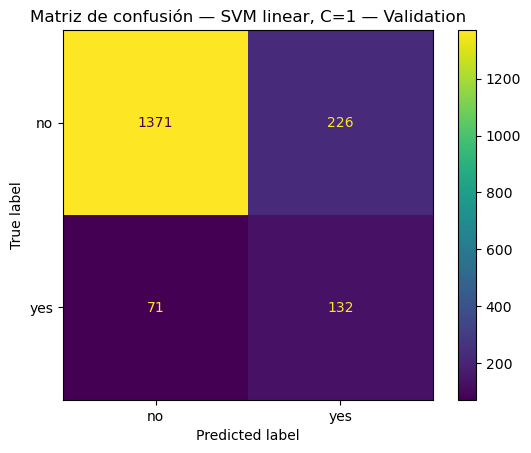

              precision    recall  f1-score   support

          no       0.95      0.86      0.90      1597
         yes       0.37      0.65      0.47       203

    accuracy                           0.83      1800
   macro avg       0.66      0.75      0.69      1800
weighted avg       0.89      0.83      0.85      1800



In [69]:
# La comparación final es entre cuatro enfoques predefinidos, no entre resultados de Test.
# F1 es una regla didáctica: cámbiala antes de evaluar Test si el costo favorece Recall/Precision.
elegido = tabla_cuatro["f1_yes"].idxmax()
modelo_final = modelos[elegido]
print("Elegido usando solo Validation:", elegido)
pred_val = modelo_final.predict(X_val)
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, display_labels=["no", "yes"], values_format="d")
plt.title(f"Matriz de confusión — {elegido} — Validation")
plt.show()
print(classification_report(y_val, pred_val, target_names=["no", "yes"], zero_division=0))


### Leer la matriz del modelo elegido

Ya sabes que **filas = realidad** y **columnas = predicción**. En la matriz del ganador de Validation: arriba a la derecha están los **FP** (predijo `yes`, era `no`); abajo a la izquierda, los **FN** (predijo `no`, era `yes`). Di en voz alta los dos conteos y luego explica su consecuencia en el escenario de llamadas.

Compara esta matriz con la del primer árbol: ¿encontramos más positivos reales?, ¿a costa de cuántos avisos equivocados? Una mejora en Recall no significa automáticamente que Precision también mejore. El color del gráfico facilita verlo, pero **los números de las cuatro casillas** sostienen la conclusión.


### De la matriz al reporte de métricas

Si la fila `yes` real contiene **FN y VP**, su suma es el número de positivos históricos; Recall usa `VP/(VP+FN)`. Si la columna `yes` predicho contiene **FP y VP**, su suma es el número de alertas positivas; Precision usa `VP/(VP+FP)`. `classification_report` calcula esos indicadores por clase y agrega **support**: cuántos contactos reales había en cada clase. No confundas *support* con el número de personas que el modelo decidió llamar.

La matriz responde «¿cómo falló este modelo en estas filas de Validation?». No determina si las llamadas valen la pena, si se comportará igual en otro país o si existe una relación causal entre una variable y contratar: esas son preguntas distintas que requieren más información.


## Evaluación final: abrir Test una sola vez

Ya escogimos un modelo usando **Validation**, con F1 como regla del ejemplo. Ahora aplicamos exactamente ese Pipeline a `X_test`, las filas reservadas desde el comienzo, y comparamos sus predicciones con `y_test`. El modelo **no se reajusta** aquí y no cambiamos sus parámetros porque alguna métrica haya bajado. Si lo hiciéramos, Test se convertiría en otra Validation y necesitaríamos nuevos contactos independientes para una evaluación final honesta.

`predict()` devuelve la clase conforme a la regla predeterminada de cada estimador; la SVM del ejemplo no entrega probabilidades calibradas. El resultado de Test es una estimación para esta muestra histórica, no una promesa sobre una próxima campaña ni una recomendación aplicable al Banco Central del Ecuador.


In [70]:
pred_test = modelo_final.predict(X_test)
pd.DataFrame([resumen(y_val, pred_val, "Validation"), resumen(y_test, pred_test, "Test")]).set_index("modelo").round(3)


,accuracy,precision_yes,recall_yes,f1_yes
modelo,,,,
Validation,0.835,0.369,0.65,0.471
Test,0.837,0.375,0.67,0.481


### ¿Cómo comparar Validation y Test?

Las dos filas de la tabla muestran **las mismas métricas**, pero sobre contactos diferentes. Empieza por la cantidad de `yes` que se detectó (Recall) y la calidad de las alertas (Precision); luego compara F1 y Accuracy. Si son parecidas, el resultado fue relativamente consistente **en esta división**. Si Test empeora, no concluyas sin más que el algoritmo «se dañó»: pueden influir las filas concretas elegidas, el pequeño número de positivos o diferencias entre grupos y periodos.

No vuelvas a escoger `k`, kernel, `C` o umbral buscando un Test más favorable. Además, como las filas se repartieron aleatoriamente, este Test **no simula un periodo futuro completo**. Para una campaña posterior necesitaríamos validar con datos posteriores y revisar qué información estaba disponible antes de cada llamada.


### ¿Y si cambia la proporción de `yes`?

Aquí cerca del 11 % de los contactos históricos fueron `yes`. A esa frecuencia se le llama **tasa base** de la clase positiva. Imagina otra campaña donde solo el 3 % contrata: incluso si el modelo detectara una fracción semejante de los `yes` reales, muchas de sus alertas podrían corresponder ahora a `no`, y **Precision podría bajar**. Por eso no debemos trasladar automáticamente una cifra de este dataset a otra población o fecha.

Un cambio en las características de las personas o en la frecuencia de las respuestas se llama **cambio de distribución** (*shift*). Un sistema aplicado tendría que comprobar periódicamente las entradas, la calidad de `y` y las métricas con datos nuevos; este notebook no demuestra que ese monitoreo ya exista.


## Actividad autónoma y comprobación de aprendizaje

Sin volver a elegir mirando Test, compara `k=5`, `15` y `31`: explica con la matriz cómo cambian **FP y FN**, no solo qué fila obtuvo más Accuracy. Contrasta la SVM lineal con RBF y dos complejidades del árbol o bosque; usa las mismas filas de Validation. Presenta una tabla de **cuatro enfoques predefinidos** y argumenta cuál error priorizarías si el tiempo de llamadas fuera limitado.

**Comprueba que puedes explicarlo sin código:** ¿qué representan filas y columnas de una matriz de confusión? ¿Por qué el baseline puede tener Accuracy alta y Recall de `yes` cero? ¿Por qué KNN y SVM necesitan cuidar la escala? ¿Qué significa el margen de SVM? ¿Por qué Test no sirve para seguir escogiendo modelos? Recuerda que estos contactos portugueses no describen una población ecuatoriana.
